Cell 0: Imports

In [64]:
# Import all required libraries

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import os

Cell 1: Tickers

In [65]:
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia

retrieval_date = '2026-11-21'
if os.path.exists(f'data/sp500_{retrieval_date}.csv'):
  sp500_df = pd.read_csv(f'data/sp500_{retrieval_date}.csv')
else:
  url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
  table = pd.read_html(url, storage_options={'User-Agent': 'Mozilla/5.0'})
  sp500_df = table[0]

  sp500_df = sp500_df[['Symbol', 'Security', 'GICS Sector', 'Date added']].copy()
  os.makedirs('data', exist_ok=True)

  sp500_df['Symbol'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
  sp500_df.to_csv(f'data/sp500_{retrieval_date}.csv', index=False)

tickers = sp500_df['Symbol'].tolist()
print('Retrieval date:',retrieval_date)
print('Total tickers extracted:', len(tickers))
sp500_df.head(10)

Retrieval date: 2026-11-21
Total tickers extracted: 503


,Symbol,Security,GICS Sector,Date added
0,MMM,3M,Industrials,1957-03-04
1,AOS,A. O. Smith,Industrials,2017-07-26
2,ABT,Abbott Laboratories,Health Care,1957-03-04
3,ABBV,AbbVie,Health Care,2012-12-31
4,ACN,Accenture,Information Technology,2011-07-06
5,ADBE,Adobe Inc.,Information Technology,1997-05-05
6,AMD,Advanced Micro Devices,Information Technology,2017-03-20
7,AES,AES Corporation,Utilities,1998-10-02
8,AFL,Aflac,Financials,1999-05-28
9,A,Agilent Technologies,Health Care,2000-06-05


In [66]:
# Part2: Load Daily Market Data via yfinance
# Download 'Close','Adj Close','Volume', 'Dividends', 'Stock Splits' and ^GSPC benchmark for all S&P 500 tickers
# Period: 01-01-2021 to 01-01-2025
start, end = '2021-01-01', '2025-01-01'
prices_file = f'data/sp500_prices_{retrieval_date}.csv.gz'

if os.path.exists(prices_file):
  df = pd.read_csv(prices_file, header=[0,1], index_col=0, parse_dates=True)
else:
  df = yf.download(tickers + ['^GSPC'], start=start, end=end, auto_adjust=False, actions=True)
  df = df[['Close','Adj Close','Volume', 'Dividends', 'Stock Splits']]
  df.to_csv(prices_file)

failed = df['Adj Close'].columns[df['Adj Close'].isna().all()].tolist()
print('pandas', pd.__version__, '\nyfinance', yf.__version__)
print('Failed tickers:', failed, 'Failed count:', len(failed))
print('Shape:', df.shape)
df.head()

pandas 2.2.3 
yfinance 0.2.66
Failed tickers: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR'] Failed count: 5
Shape: (1005, 2510)


Price            Close                                                  \
Ticker               A        AAPL        ABBV        ABNB         ABT   
Date                                                                     
2021-01-04  118.639999  129.410004  105.410004  139.149994  109.110001   
2021-01-05  119.610001  131.009995  106.500000  148.300003  110.459999   
2021-01-06  122.889999  126.599998  105.580002  142.770004  110.230003   
2021-01-07  126.160004  130.919998  106.709999  151.270004  111.300003   
2021-01-08  127.059998  132.050003  107.269997  149.770004  111.610001   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  34.900002  256.459991  485.339996  146.020004  49.869999  ...   
2021-01-05  35.040001  257.920013  485.690002  148.630005  50.840000  ...   
2021-01-06  36.580002  260.739990  466.309998  149.300003  52.900002  ...   
2021-01-07  36.240002  263.200012  477.739990  155.610001  52.430000  ...   
2021-01-08  36.439999  264.160004  485.100006  156.740005  52.570000  ...   

Price      Stock Splits                                                
Ticker             WYNN  XEL  XOM  XYL  XYZ  YUM  ZBH ZBRA  ZTS ^GSPC  
Date                                                                   
2021-01-04          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-05          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-06          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-07          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  
2021-01-08          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   0.0  

[5 rows x 2510 columns]

In [67]:
# Part 3
excluded = {ticker:'no price data in study period' for ticker in failed}
print('Excluded tickers:', excluded)
print('Duplicate days:', df.index.duplicated().sum())

missing = df['Adj Close'].drop(columns=excluded).isna().sum()
print(missing[missing>0])



Excluded tickers: {'FDXF': 'no price data in study period', 'HONA': 'no price data in study period', 'Q': 'no price data in study period', 'SNDK': 'no price data in study period', 'VYLR': 'no price data in study period'}
Duplicate days: 0
Ticker
APP      70
CEG     263
COIN     69
EXE      26
GEHC    492
GEV     812
HOOD    143
RDDT    808
SOLV    811
VLTO    692
dtype: int64


In [68]:
late = missing[missing > 0]
leading = (df['Adj Close'][late.index].notna().cumsum() ==0).sum()
print((leading == late).all())

True


In [69]:
print(df['Volume'].index[df['Volume']['FERG']<=0])
print(df['Volume'].index[df['Volume']['SW']<=0])

DatetimeIndex(['2021-01-07', '2021-01-08', '2021-01-12', '2021-01-13',
               '2021-01-14', '2021-01-15', '2021-01-20', '2021-01-21',
               '2021-01-22', '2021-01-25', '2021-01-26', '2021-01-28',
               '2021-01-29', '2021-02-01', '2021-02-02', '2021-02-03',
               '2021-02-09', '2021-02-10', '2021-02-11', '2021-02-12',
               '2021-02-16', '2021-02-19', '2021-02-22', '2021-02-23',
               '2021-03-01', '2021-03-04', '2021-03-05'],
              dtype='datetime64[ns]', name='Date', freq=None)
DatetimeIndex(['2021-01-05', '2021-01-06', '2021-01-12', '2021-01-13',
               '2021-01-19', '2021-01-20', '2021-01-21', '2021-01-22',
               '2021-01-25', '2021-01-26',
               ...
               '2024-06-05', '2024-06-07', '2024-06-10', '2024-06-11',
               '2024-06-12', '2024-06-13', '2024-06-17', '2024-06-25',
               '2024-07-02', '2024-07-05'],
              dtype='datetime64[ns]', name='Date', length=424, f

In [70]:
excluded.update({ticker: 'listed during study period' for ticker in late.index})
print(len(excluded))

15


In [71]:
excluded.update({'FERG': 'listed during study period (zero volume before listing)',
                 'SW': 'listed during study period (zero volume before listing)'})
print(len(excluded))

17


In [72]:
valid = df.drop(columns=excluded, level=1)
print('Valid left:', valid['Adj Close'].shape[1])
print('Missing:', valid.isna().sum().sum())
print('Non-positive values:', (valid[['Close', 'Adj Close']] <=0).sum().sum())

bad_volume = (valid['Volume'] <= 0).sum()
print('Bad volume:', bad_volume[bad_volume > 0])

Valid left: 487
Missing: 0
Non-positive values: 0
Bad volume: Ticker
^GSPC    1
dtype: int64


In [73]:
split_tickers = valid['Stock Splits'].columns[(valid['Stock Splits']>0).any()].tolist()
print('Tickers split:', len(split_tickers))

close_returns = valid['Close'].pct_change(fill_method=None)
split_day_move = close_returns[valid['Stock Splits'] > 0].abs().max().max()
print('Largest Close move on a split date:', round(split_day_move,4))

dividend_payers = (valid['Dividends'] > 0).any().sum()
print('Shares paying dividends:', dividend_payers)

jumps = close_returns.abs().max()
big_jumps = jumps[jumps>0.4]
print('One-day moves above 40%',big_jumps.round(3).to_dict())

Tickers split: 53
Largest Close move on a split date: 0.0766
Shares paying dividends: 392
One-day moves above 40% {'BE': 0.592, 'CVNA': 0.56, 'DXCM': 0.407, 'GL': 0.531}


In [74]:
print('Big movers that also split: ', set(big_jumps.index) & set(split_tickers))
print('Dates of big moves: ', valid['Close'][big_jumps.index].pct_change(fill_method=None).abs().idxmax())

Big movers that also split:  {'DXCM'}
Dates of big moves:  Ticker
BE     2024-11-15
CVNA   2023-06-08
DXCM   2024-07-26
GL     2024-04-11
dtype: datetime64[ns]


In [75]:
dxcm = valid['Stock Splits']['DXCM']
print('DXCM split:', dxcm[dxcm>0])

DXCM split: Date
2022-06-13    4.0
Name: DXCM, dtype: float64


In [76]:
exclusions = pd.DataFrame(excluded.items(), columns=['Symbol', 'Reason'])
exclusions = exclusions.merge(sp500_df, on='Symbol', how='left')
exclusions.to_csv(f'data/sp500_exclusions_{retrieval_date}.csv', index=False)
exclusions

,Symbol,Reason,Security,GICS Sector,Date added
0,FDXF,no price data in study period,FedEx Freight,Industrials,2026-06-01
1,HONA,no price data in study period,Honeywell Aerospace,Industrials,2026-06-29
2,Q,no price data in study period,Qnity Electronics,Information Technology,2025-11-03
3,SNDK,no price data in study period,Sandisk,Information Technology,2025-11-28
4,VYLR,no price data in study period,Vylor,Consumer Staples,2026-10-01
5,APP,listed during study period,AppLovin,Communication Services,2025-09-22
6,CEG,listed during study period,Constellation Energy,Utilities,2022-02-02
7,COIN,listed during study period,Coinbase,Financials,2025-05-19
8,EXE,listed during study period,Expand Energy,Energy,2025-03-24
9,GEHC,listed during study period,GE HealthCare,Health Care,2023-01-04


In [77]:
# Part 4
weekly_prices = valid['Adj Close'].resample('W-FRI').last()
weekly_prices = weekly_prices.loc[:'2024-12-27'] # 2024-12-27 is the last complete week
weekly_returns = weekly_prices.pct_change(fill_method=None).iloc[1:]

mean_return = weekly_returns.drop(columns='^GSPC').mean()
print('NaN count:', weekly_returns.isna().sum().sum())
print('Number of weeks:', len(weekly_returns))

NaN count: 0
Number of weeks: 207


In [78]:
# Part 5
market = weekly_returns['^GSPC']
beta = weekly_returns.cov()['^GSPC'] / market.var()
print('Market beta:', beta['^GSPC'])

beta = beta.drop('^GSPC')

print('Paired weeks per share',weekly_returns.notna().sum().unique())

Market beta: 1.0
Paired weeks per share [207]


In [79]:
# Part 6
volume = valid['Volume'].drop(columns='^GSPC')
close = valid['Close'].drop(columns='^GSPC')

obs_date = pd.Timestamp('2024-12-31')
print('Common end date:',volume.index[-1] == obs_date)

avg_volume = volume.shift(1).rolling(20).mean()
high = volume > 2 * avg_volume
print('Total high-voulme days:',high.sum().sum())

Common end date: True
Total high-voulme days: 18280


In [80]:
frequency = high.tail(60).sum()
monetary = (close*volume).tail(60).sum()
last_event = high.iloc[::-1].idxmax().where(high.any())
recency = (obs_date - last_event).dt.days
rfm = pd.DataFrame({'Recency': recency,'Frequency': frequency, 'Monetary': monetary})

print('Missing recency:',rfm.index[rfm['Recency'].isna()])
rfm.describe()

Missing recency: Index([], dtype='object', name='Ticker')


,Recency,Frequency,Monetary
count,486.000000,486.000000,4.860000e+02
mean,20.407407,2.989712,3.940419e+10
std,21.342438,1.330800,1.291388e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.019517e+10
50%,11.000000,3.000000,1.668382e+10
75%,14.750000,4.000000,3.227689e+10
max,222.000000,8.000000,1.847697e+12


In [81]:
print('Missing baselines last 60 sessions',avg_volume.tail(60).isna().sum().sum())
features = pd.DataFrame({'Recency': recency,'Frequency': frequency, 'Monetary': monetary, 'Beta': beta, 'Mean_return': mean_return})

features.to_csv(f'data/features_{retrieval_date}.csv')
print('Features skew:',features.skew())
features.describe()

Missing baselines last 60 sessions 0
Features skew: Recency         3.645784
Frequency       0.424735
Monetary       11.683797
Beta            1.103649
Mean_return     0.867516
dtype: float64


,Recency,Frequency,Monetary,Beta,Mean_return
count,486.000000,486.000000,4.860000e+02,486.000000,486.000000
mean,20.407407,2.989712,3.940419e+10,0.973695,0.002857
std,21.342438,1.330800,1.291388e+11,0.407339,0.002652
min,4.000000,0.000000,1.297483e+09,0.055453,-0.004468
25%,11.000000,2.000000,1.019517e+10,0.666599,0.001182
50%,11.000000,3.000000,1.668382e+10,0.950609,0.002619
75%,14.750000,4.000000,3.227689e+10,1.179538,0.004207
max,222.000000,8.000000,1.847697e+12,3.778560,0.017772


In [82]:
day = last_event['AAPL']

print('AAPL last event:', day.date())
print('Observation date', obs_date.date())
print('Recency (days):', recency['AAPL'])

print('Volume on event day:', volume.loc[day, 'AAPL'])
print('20-session average:', avg_volume.loc[day, 'AAPL'])
print('Threshold (2x average):', 2*avg_volume.loc[day, 'AAPL'])

manual_avg = volume['AAPL'].loc[:day].iloc[-21:-1].mean()
print('Manual 20-session average:', manual_avg)

print('Frequency:', frequency['AAPL'])
print('Monetary (USD):', monetary['AAPL'])

AAPL last event: 2024-12-20
Observation date 2024-12-31
Recency (days): 11
Volume on event day: 147495300
20-session average: 45004605.0
Threshold (2x average): 90009210.0
Manual 20-session average: 45004605.0
Frequency: 2
Monetary (USD): 623303377706.5842


In [83]:
print('Shares added after start:', (pd.to_datetime(sp500_df.set_index('Symbol').loc[features.index, 'Date added']) > '2021-01-01').sum())

Shares added after start: 72


In [84]:
print('Shares whose last event was 20 Dec 2024:', (last_event == '2024-12-20').sum())

Shares whose last event was 20 Dec 2024: 353


In [85]:
print('Shares with F = 0:', (frequency == 0).sum())

Shares with F = 0: 10


In [86]:
print('^GSPC mean weekly return:', weekly_returns['^GSPC'].mean())

^GSPC mean weekly return: 0.002398425852406388


In [87]:
x = weekly_returns['^GSPC']
y = weekly_returns['AAPL']

print('np.polyfit beta (AAPL):', np.polyfit(x, y, 1)[0])
print('cov/var beta (AAPL):', beta['AAPL'])

np.polyfit beta (AAPL): 1.1748360046001143
cov/var beta (AAPL): 1.1748360046001138


In [88]:
p0 = weekly_prices['AAPL'].iloc[0]
p1 = weekly_prices['AAPL'].iloc[1]

print('Dates:', weekly_prices.index[0].date(), '->', weekly_prices.index[1].date())
print('Manual return:', p1 / p0 - 1)
print('pct_change return:', weekly_returns['AAPL'].iloc[0])

Dates: 2021-01-08 -> 2021-01-15
Manual return: -0.03718309110892759
pct_change return: -0.03718309110892759


In [89]:
aapl_high = high['AAPL'].tail(60)
print('AAPL qualifying dates:', aapl_high[aapl_high].index)

print('AAPL Close x Volume, 31 December:', close['AAPL'].iloc[-1] * volume['AAPL'].iloc[-1])

AAPL qualifying dates: DatetimeIndex(['2024-11-25', '2024-12-20'], dtype='datetime64[ns]', name='Date', freq=None)
AAPL Close x Volume, 31 December: 9886756821.70868


In [90]:
tbl_data = features.copy()

tbl_data['Monetary'] = tbl_data['Monetary'] / 1e9
tbl_data['Mean_return'] = tbl_data['Mean_return'] * 100

tbl = tbl_data.describe()
tbl.loc['skew'] = tbl_data.skew()

display(tbl.round(3))

,Recency,Frequency,Monetary,Beta,Mean_return
count,486.000,486.000,486.000,486.000,486.000
mean,20.407,2.990,39.404,0.974,0.286
std,21.342,1.331,129.139,0.407,0.265
min,4.000,0.000,1.297,0.055,-0.447
25%,11.000,2.000,10.195,0.667,0.118
50%,11.000,3.000,16.684,0.951,0.262
75%,14.750,4.000,32.277,1.180,0.421
max,222.000,8.000,1847.697,3.779,1.777
skew,3.646,0.425,11.684,1.104,0.868




---

part 7

In [91]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
import sklearn

print('sklearn version:', sklearn.__version__)

os.makedirs('figures', exist_ok=True)

sklearn version: 1.6.1


## 2.1 Feature preparation

In [92]:
features = pd.read_csv(f'data/features_{retrieval_date}.csv', index_col=0)

risk_return = features[['Mean_return', 'Beta']]
activity = features[['Recency', 'Frequency', 'Monetary']].copy()
activity['Monetary'] = np.log1p(activity['Monetary'])

print('risk_return shape:', risk_return.shape)
print('activity shape:', activity.shape)
print('Same index:', risk_return.index.equals(activity.index))
print('Missing values in features:', features.isna().sum().sum())

risk_return shape: (486, 2)
activity shape: (486, 3)
Same index: True
Missing values in features: 0


In [93]:
print('Raw Monetary skew:', round(features['Monetary'].skew(), 2))
print('Log Monetary skew:', round(activity['Monetary'].skew(), 2))

print('\nSkew of activity:')
print(activity.skew().round(2))

print('\nSkew of risk_return:')
print(risk_return.skew().round(2))

z_act = (activity - activity.mean()) / activity.std()
z_rr = (risk_return - risk_return.mean()) / risk_return.std()

print('\nOutliers beyond ±3 SD (activity):')
print((z_act.abs() > 3).sum())

print('\nOutliers beyond ±3 SD (risk_return):')
print((z_rr.abs() > 3).sum())

Raw Monetary skew: 11.68
Log Monetary skew: 1.08

Skew of activity:
Recency      3.65
Frequency    0.42
Monetary     1.08
dtype: float64

Skew of risk_return:
Mean_return    0.87
Beta           1.10
dtype: float64

Outliers beyond ±3 SD (activity):
Recency      11
Frequency     5
Monetary      7
dtype: int64

Outliers beyond ±3 SD (risk_return):
Mean_return    6
Beta           2
dtype: int64


In [94]:
X_rr = StandardScaler().fit_transform(risk_return)
X_act = StandardScaler().fit_transform(activity)

print('risk_return means:', X_rr.mean(axis=0).round(3))
print('risk_return stds: ', X_rr.std(axis=0).round(3))
print('activity means:   ', X_act.mean(axis=0).round(3))
print('activity stds:    ', X_act.std(axis=0).round(3))

risk_return means: [ 0. -0.]
risk_return stds:  [1. 1.]
activity means:    [-0. -0. -0.]
activity stds:     [1. 1. 1.]


## 2.2 Hierarchical clustering



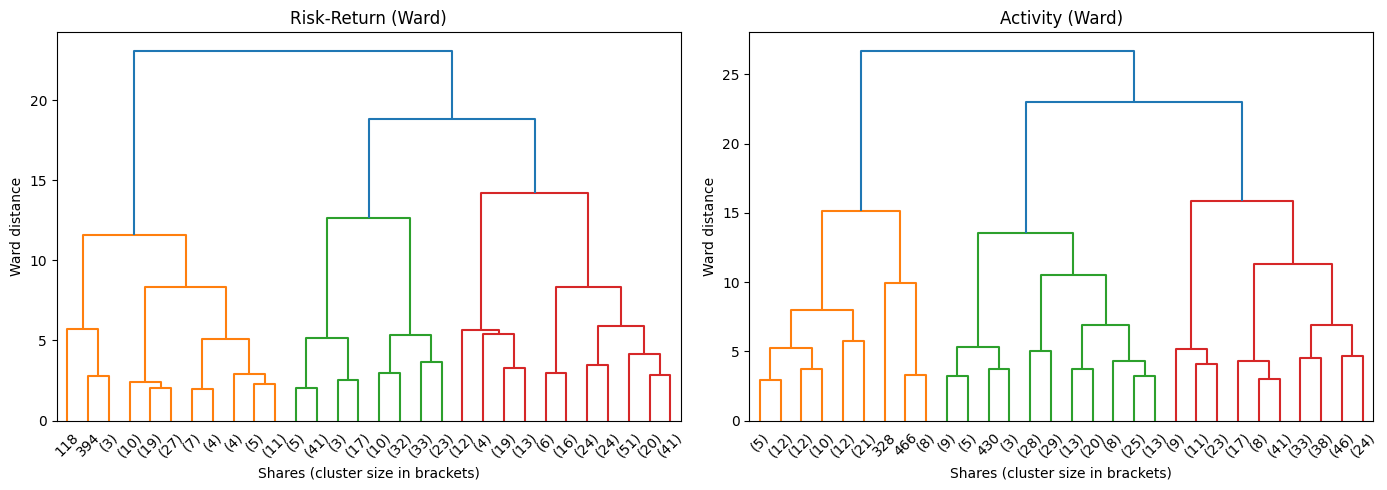

In [95]:
Z_rr = linkage(X_rr, method='ward')
Z_act = linkage(X_act, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dendrogram(Z_rr, ax=axes[0], truncate_mode='lastp', p=30)
axes[0].set_title('Risk-Return (Ward)')
axes[0].set_xlabel('Shares (cluster size in brackets)')
axes[0].set_ylabel('Ward distance')

dendrogram(Z_act, ax=axes[1], truncate_mode='lastp', p=30)
axes[1].set_title('Activity (Ward)')
axes[1].set_xlabel('Shares (cluster size in brackets)')
axes[1].set_ylabel('Ward distance')

plt.tight_layout()
plt.savefig('figures/dendrograms.png', dpi=150)
plt.show()

In [96]:
def evaluate_k(X, Z):
    rows = []
    for k in range(2, 9):
        ward_labels = cut_tree(Z, n_clusters=k).ravel()
        km = KMeans(n_clusters=k, n_init=10, random_state=158).fit(X)
        rows.append({
            'k': k,
            'ward_silhouette': silhouette_score(X, ward_labels),
            'ward_sizes': np.bincount(ward_labels).tolist(),
            'km_silhouette': silhouette_score(X, km.labels_),
            'km_inertia': km.inertia_,
            'km_sizes': np.bincount(km.labels_).tolist()
        })
    return pd.DataFrame(rows)

eval_rr = evaluate_k(X_rr, Z_rr)
eval_act = evaluate_k(X_act, Z_act)

print('Risk-Return diagnostics:')
display(eval_rr.round(3))

print('\nActivity diagnostics:')
display(eval_act.round(3))

Risk-Return diagnostics:


,k,ward_silhouette,ward_sizes,km_silhouette,km_inertia,km_sizes
0,2,0.339,"[394, 92]",0.387,621.634,"[143, 343]"
1,3,0.274,"[230, 92, 164]",0.329,461.179,"[165, 202, 119]"
2,4,0.282,"[182, 92, 164, 48]",0.326,371.559,"[154, 132, 41, 159]"
3,5,0.304,"[182, 92, 98, 48, 66]",0.338,310.094,"[30, 126, 160, 55, 115]"
4,6,0.320,"[182, 87, 98, 48, 66, 5]",0.326,265.709,"[56, 76, 85, 20, 116, 133]"
5,7,0.324,"[160, 87, 98, 48, 66, 22, 5]",0.352,227.794,"[43, 140, 85, 15, 80, 41, 82]"
6,8,0.321,"[160, 56, 98, 48, 66, 22, 31, 5]",0.353,195.983,"[81, 144, 82, 5, 77, 33, 36, 28]"



Activity diagnostics:


,k,ward_silhouette,ward_sizes,km_silhouette,km_inertia,km_sizes
0,2,0.368,"[404, 82]",0.423,1066.832,"[418, 68]"
1,3,0.304,"[250, 154, 82]",0.325,796.630,"[271, 152, 63]"
2,4,0.289,"[207, 154, 82, 43]",0.340,609.939,"[122, 93, 211, 60]"
3,5,0.305,"[207, 154, 72, 43, 10]",0.358,514.714,"[87, 11, 68, 198, 122]"
4,6,0.314,"[207, 18, 136, 72, 43, 10]",0.346,437.422,"[11, 41, 141, 104, 69, 120]"
5,7,0.292,"[66, 18, 136, 141, 72, 43, 10]",0.347,386.286,"[120, 68, 41, 141, 104, 11, 1]"
6,8,0.302,"[66, 18, 79, 57, 141, 72, 43, 10]",0.328,344.724,"[68, 62, 17, 1, 102, 15, 88, 133]"


## 2.3 K-means



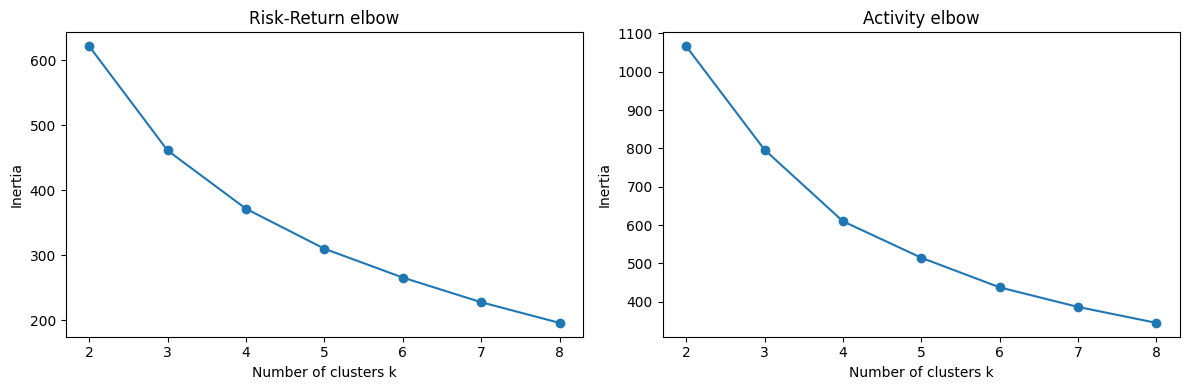

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(eval_rr['k'], eval_rr['km_inertia'], marker='o')
axes[0].set_title('Risk-Return elbow')
axes[0].set_xlabel('Number of clusters k')
axes[0].set_ylabel('Inertia')

axes[1].plot(eval_act['k'], eval_act['km_inertia'], marker='o')
axes[1].set_title('Activity elbow')
axes[1].set_xlabel('Number of clusters k')
axes[1].set_ylabel('Inertia')

plt.tight_layout()
plt.savefig('figures/elbow.png', dpi=150)
plt.show()

In [98]:
k_rr_ward = 5
k_rr_km = 5
k_act_ward = 4
k_act_km = 4

clusters = pd.DataFrame(index=features.index)

clusters['rr_ward'] = cut_tree(Z_rr, n_clusters=k_rr_ward).ravel() + 1
clusters['rr_km'] = KMeans(n_clusters=k_rr_km, n_init=10, random_state=158).fit_predict(X_rr) + 1
clusters['act_ward'] = cut_tree(Z_act, n_clusters=k_act_ward).ravel() + 1
clusters['act_km'] = KMeans(n_clusters=k_act_km, n_init=10, random_state=158).fit_predict(X_act) + 1

clusters.to_csv(f'data/clusters_{retrieval_date}.csv')
print('Cluster assignment counts:')
print(clusters.apply(pd.Series.value_counts).fillna(0).astype(int))

km_check_rr = KMeans(n_clusters=k_rr_km, n_init=10, random_state=0).fit_predict(X_rr)
print('ARI risk-return K-means, seed 158 vs 0:', round(adjusted_rand_score(clusters['rr_km'], km_check_rr), 3))

km_check_act = KMeans(n_clusters=k_act_km, n_init=10, random_state=0).fit_predict(X_act)
print('ARI activity K-means, seed 158 vs 0:', round(adjusted_rand_score(clusters['act_km'], km_check_act), 3))

Cluster assignment counts:
   rr_ward  rr_km  act_ward  act_km
1      182     30       207     122
2       92    126       154      93
3       98    160        82     211
4       48     55        43      60
5       66    115         0       0
ARI risk-return K-means, seed 158 vs 0: 0.991
ARI activity K-means, seed 158 vs 0: 0.997


## 2.4 Cluster profiles and algorithm comparison

In [99]:
def profile(col):
    p = features.groupby(clusters[col]).mean()
    p['Monetary'] = p['Monetary'] / 1e9
    p['Mean_return'] = p['Mean_return'] * 100
    p['Size'] = clusters[col].value_counts()
    return p.round(3)

print('Risk-Return Ward profiles:')
display(profile('rr_ward'))

print('\nRisk-Return K-means profiles:')
display(profile('rr_km'))

print('\nActivity Ward profiles:')
display(profile('act_ward'))

print('\nActivity K-means profiles:')
display(profile('act_km'))

Risk-Return Ward profiles:


,Recency,Frequency,Monetary,Beta,Mean_return,Size
rr_ward,,,,,,
1,17.714,3.011,19.788,0.973,0.132,182
2,23.674,3.196,78.781,1.298,0.632,92
3,16.908,2.704,24.691,0.710,0.422,98
4,23.542,3.229,86.935,1.628,0.200,48
5,26.197,2.894,25.888,0.439,0.088,66



Risk-Return K-means profiles:


,Recency,Frequency,Monetary,Beta,Mean_return,Size
rr_km,,,,,,
1,28.900,3.200,112.451,1.536,0.903,30
2,22.206,2.913,24.228,0.525,0.226,126
3,17.031,2.894,37.041,1.004,0.422,160
4,24.382,3.145,81.975,1.599,0.218,55
5,19.017,3.078,19.904,0.977,0.032,115



Activity Ward profiles:


,Recency,Frequency,Monetary,Beta,Mean_return,Size
act_ward,,,,,,
1,11.140,2.942,11.100,0.926,0.247,207
2,13.682,2.864,80.145,1.010,0.338,154
3,58.305,2.098,47.159,1.009,0.286,82
4,16.837,5.372,14.962,1.008,0.281,43



Activity K-means profiles:


,Recency,Frequency,Monetary,Beta,Mean_return,Size
act_km,,,,,,
1,13.943,4.549,15.015,0.966,0.257,122
2,15.516,3.237,115.550,1.061,0.337,93
3,13.275,2.365,15.106,0.939,0.276,211
4,66.217,1.633,56.417,0.974,0.301,60


PCA explained variance ratio: [0.458 0.336]


,Recency,Frequency,Monetary
PC1,0.711,-0.650,0.268
PC2,0.023,0.402,0.915


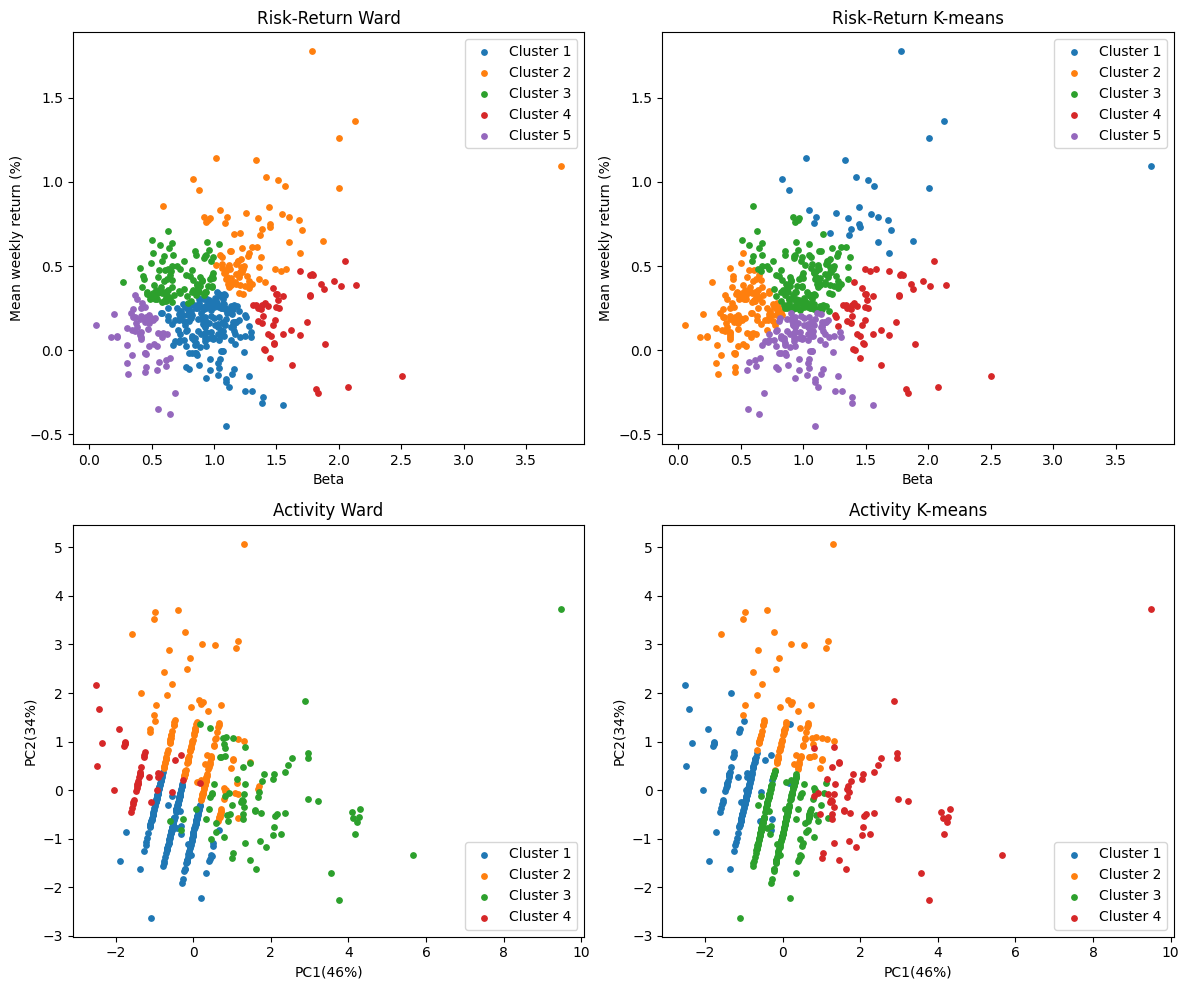

In [100]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Top row: risk-return (no PCA needed)
for ax, col, title in zip(axes[0], ['rr_ward', 'rr_km'], ['Risk-Return Ward', 'Risk-Return K-means']):
    labels = clusters[col]
    for c in sorted(labels.unique()):
        mask = labels == c
        ax.scatter(features.loc[mask, 'Beta'],
                   features.loc[mask, 'Mean_return'] * 100,
                   label=f'Cluster {c}', s=15)
    ax.set_title(title)
    ax.set_xlabel('Beta')
    ax.set_ylabel('Mean weekly return (%)')
    ax.legend()

# Bottom row: activity (PCA)
pca = PCA(n_components=2, random_state=158)
pcs = pca.fit_transform(X_act)
print('PCA explained variance ratio:', pca.explained_variance_ratio_.round(3))
display(pd.DataFrame(pca.components_, columns=activity.columns, index=['PC1', 'PC2']).round(3))

for ax, col, title in zip(axes[1], ['act_ward', 'act_km'], ['Activity Ward', 'Activity K-means']):
    labels = clusters[col]
    for c in sorted(labels.unique()):
        mask = labels == c
        ax.scatter(pcs[mask, 0], pcs[mask, 1], label=f'Cluster {c}', s=15)
    ax.set_title(title)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
    ax.legend()

plt.tight_layout()
plt.savefig('figures/cluster_plots.png', dpi=150)
plt.show()

In [101]:
print('ARI Risk-Return (Ward vs K-means):',
      round(adjusted_rand_score(clusters['rr_ward'], clusters['rr_km']), 3))

print('\nCrosstab Risk-Return:')
display(pd.crosstab(clusters['rr_ward'], clusters['rr_km']))

print('\nARI Activity (Ward vs K-means):',
      round(adjusted_rand_score(clusters['act_ward'], clusters['act_km']), 3))

print('\nCrosstab Activity:')
display(pd.crosstab(clusters['act_ward'], clusters['act_km']))

ARI Risk-Return (Ward vs K-means): 0.335

Crosstab Risk-Return:


rr_km,1,2,3,4,5
rr_ward,,,,,
1,0,23,49,3,107
2,30,0,58,4,0
3,0,45,53,0,0
4,0,0,0,48,0
5,0,58,0,0,8



ARI Activity (Ward vs K-means): 0.344

Crosstab Activity:


act_km,1,2,3,4
act_ward,,,,
1,61,0,146,0
2,14,85,51,4
3,4,8,14,56
4,43,0,0,0


## 2.5.1 RFM correlations

In [102]:
print('Correlations (Recency, Frequency, log1p Monetary):')
print(activity.corr().round(3))

Correlations (Recency, Frequency, log1p Monetary):
           Recency  Frequency  Monetary
Recency      1.000     -0.346     0.152
Frequency   -0.346      1.000     0.013
Monetary     0.152      0.013     1.000


## 2.5.2 Effect of removing Monetary

In [104]:
X_rf = StandardScaler().fit_transform(activity[['Recency', 'Frequency']])
clusters['rf_ward'] = cut_tree(linkage(X_rf, method='ward'), n_clusters=k_act_ward).ravel() + 1

print('ARI (RF vs full Activity Ward):',
      round(adjusted_rand_score(clusters['rf_ward'], clusters['act_ward']), 3))

print('\nMedian Monetary (USD bn), full Activity Ward:')
print((features.groupby(clusters['act_ward'])['Monetary'].median() / 1e9).round(2))

print('\nMedian Monetary (USD bn), RF only Ward:')
print((features.groupby(clusters['rf_ward'])['Monetary'].median() / 1e9).round(2))

print('\nCrosstab (Activity Ward vs RF Ward):')
display(pd.crosstab(clusters['act_ward'], clusters['rf_ward']))

print('\nRF only Ward profiles:')
display(profile('rf_ward'))

clusters.to_csv(f'data/clusters_{retrieval_date}.csv')

ARI (RF vs full Activity Ward): 0.203

Median Monetary (USD bn), full Activity Ward:
act_ward
1    10.79
2    39.70
3    17.85
4    14.43
Name: Monetary, dtype: float64

Median Monetary (USD bn), RF only Ward:
rf_ward
1    17.70
2    14.86
3    20.13
4    23.79
Name: Monetary, dtype: float64

Crosstab (Activity Ward vs RF Ward):


rf_ward,1,2,3,4
act_ward,,,,
1,66,141,0,0
2,59,86,9,0
3,0,3,69,10
4,0,42,1,0



RF only Ward profiles:


,Recency,Frequency,Monetary,Beta,Mean_return,Size
rf_ward,,,,,,
1,11.040,1.800,34.338,0.932,0.287,125
2,12.882,3.857,39.401,0.984,0.281,272
3,48.937,2.266,27.136,1.033,0.295,79
4,116.800,0.000,199.742,0.760,0.317,10
